# Source-petal Poisson problem — Publication post-processing

Publication plot for the flower geometry and manufactured field from the supplied
MATLAB example, solved with the infinite-width Gaussian-RBF kernel method.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kapi_onet_publication_style import (
    DOUBLE_COLUMN_WIDTH, BLACK, CMAP_SOLUTION, CMAP_MAGNITUDE,
    format_colorbar, save_figure
)

In [2]:
f=Path("INF_RBF_POISSON_PETAL_SOURCE_GEOM_results.npz")
if not f.exists():
    raise FileNotFoundError("Run INF_RBF_POISSON_PETAL_SOURCE_GEOM.ipynb first.")
S=np.load(f,allow_pickle=False)

AbsErr=np.abs(S["Ug"]-S["Ue"])
AbsRes=np.abs(S["Rg"])

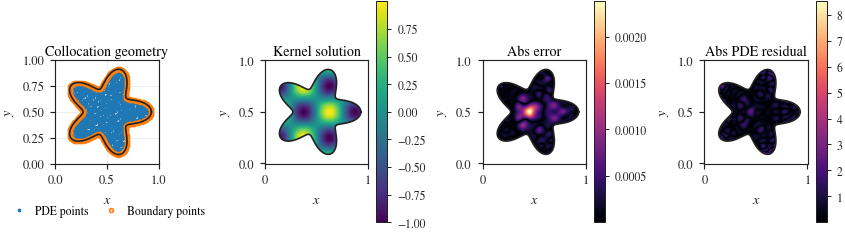

Saved:
  PoissonPetal_SourceGeometry_1x4.pdf
  PoissonPetal_SourceGeometry_1x4.png


In [3]:
fig,axes=plt.subplots(
    1,4,
    figsize=(DOUBLE_COLUMN_WIDTH,DOUBLE_COLUMN_WIDTH*0.28),
    constrained_layout=True
)

ax=axes[0]
ax.plot(S["xP"],S["yP"],".",ms=2.5,label="PDE points")
ax.plot(S["xB"],S["yB"],"o",ms=2.3,mfc="none",label="Boundary points")
ax.plot(S["xbnd"],S["ybnd"],color=BLACK,lw=1.0)
ax.set_aspect("equal")
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$y$")
ax.set_title("Collocation geometry")
ax.grid(True)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.35),
    ncol=2,
    borderaxespad=0.0
)

ax=axes[1]
im=ax.pcolormesh(S["Xg"],S["Yg"],np.ma.masked_invalid(S["Ug"]),
                 shading="auto",cmap=CMAP_SOLUTION)
ax.plot(S["xbnd"],S["ybnd"],color=BLACK,lw=1.0)
ax.set_aspect("equal")
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$y$")
ax.set_title("Kernel solution")
cb=fig.colorbar(im,ax=ax); format_colorbar(cb)

ax=axes[2]
im=ax.pcolormesh(S["Xg"],S["Yg"],np.ma.masked_invalid(AbsErr),
                 shading="auto",cmap=CMAP_MAGNITUDE)
ax.plot(S["xbnd"],S["ybnd"],color=BLACK,lw=1.0)
ax.set_aspect("equal")
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$y$")
ax.set_title("Abs error")
cb=fig.colorbar(im,ax=ax); format_colorbar(cb)

ax=axes[3]
im=ax.pcolormesh(S["Xg"],S["Yg"],np.ma.masked_invalid(AbsRes),
                 shading="auto",cmap=CMAP_MAGNITUDE)
ax.plot(S["xbnd"],S["ybnd"],color=BLACK,lw=1.0)
ax.set_aspect("equal")
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$y$")
ax.set_title("Abs PDE residual")
cb=fig.colorbar(im,ax=ax); format_colorbar(cb)

saved=save_figure(fig,"PoissonPetal_SourceGeometry_1x4",formats=("pdf","png"))
plt.show()
print("Saved:",*saved,sep="\n  ")

In [4]:
row={
    "Case":"Poisson petal",
    "Equation":"-Delta u = (kx^2+ky^2) u_exact",
    "Geometry":"r(theta)=0.33+0.10 cos(5 theta), center=(0.5,0.5)",
    "Boundary":"u = u_exact",
    "kx":float(S["kx"]),
    "ky":float(S["ky"]),
    "PDE_Points":int(S["Np"]),
    "Boundary_Points":int(S["Nb"]),
    "Boundary_Rank":int(S["rankB"]),
    "Null_Dimension":int(S["Q"].shape[1]),
    "Sigma":float(S["sigma"]),
    "RMSE":float(S["rmse"]),
    "MaxError":float(S["max_error"]),
    "BC_Train_Max":float(S["bc_train_max"]),
    "BC_Dense_Max":float(S["bc_dense_max"]),
    "Residual_RMS":float(S["res_rms"]),
    "Residual_Max":float(S["res_max"]),
}
T=pd.DataFrame([row])
T.to_csv("PoissonPetal_SourceGeometry_Table.csv",index=False)
display(T)

,Case,Equation,Geometry,Boundary,kx,ky,PDE_Points,Boundary_Points,Boundary_Rank,Null_Dimension,Sigma,RMSE,MaxError,BC_Train_Max,BC_Dense_Max,Residual_RMS,Residual_Max
0,Poisson petal,-Delta u = (kx^2+ky^2) u_exact,"r(theta)=0.33+0.10 cos(5 theta), center=(0.5,0.5)",u = u_exact,12.566371,12.566371,800,340,140,1000,0.075,0.000432,0.002371,0.000022,0.000022,0.732324,8.793812
